In [ ]:



# STEP 1: PREPROCESSING

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Augment training data + normalize
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1
)

# Val data — only normalize, never augment
val_datagen = ImageDataGenerator(rescale=1.0/255)

train_data = train_datagen.flow_from_directory(
    '/content/dataset/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_data = val_datagen.flow_from_directory(
    '/content/dataset/val',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

print("Class mapping:", train_data.class_indices)

Found 275 images belonging to 2 classes.
Found 70 images belonging to 2 classes.
Class mapping: {'cat': 0, 'dog': 1}


In [ ]:

# STEP 2: DATA SPLITTING


total = train_data.samples + val_data.samples
train_pct = train_data.samples / total * 100
val_pct   = val_data.samples   / total * 100

print(f"Total images   : {total}")
print(f"Training set   : {train_data.samples} images ({train_pct:.1f}%)")
print(f"Validation set : {val_data.samples} images ({val_pct:.1f}%)")
print(f"Split ratio    : {train_pct:.0f}/{val_pct:.0f} (Train/Val)")



Total images   : 345
Training set   : 275 images (79.7%)
Validation set : 70 images (20.3%)
Split ratio    : 80/20 (Train/Val)


In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

model = Sequential([
    # Block 1 - detect basic edges and textures
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(128, 128, 3)),
    BatchNormalization(),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    # Block 2 - detect complex patterns (ears, eyes)
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    # Block 3 - detect high-level features (fur texture, face shape)
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    # Block 4 - detect abstract features (overall body structure)
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    # Classifier
    Flatten(),
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     8,389,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,04

 Total params: 9,696,929 (36.99 MB)

 Trainable params: 9,694,945 (36.98 MB)

 Non-trainable params: 1,984 (7.75 KB)

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 52s 5s/step - accuracy: 0.5200 - loss: 0.9952 - val_accuracy: 0.6571 - val_loss: 0.6530
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 46s 5s/step - accuracy: 0.5964 - loss: 0.8173 - val_accuracy: 0.6571 - val_loss: 0.6280
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 45s 5s/step - accuracy: 0.6509 - loss: 0.7795 - val_accuracy: 0.3714 - val_loss: 0.7076
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 47s 5s/step - accuracy: 0.6145 - loss: 0.7762 - val_accuracy: 0.3429 - val_loss: 0.7247
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 45s 5s/step - accuracy: 0.6327 - loss: 0.6974 - val_accuracy: 0.5143 - val_loss: 0.6907


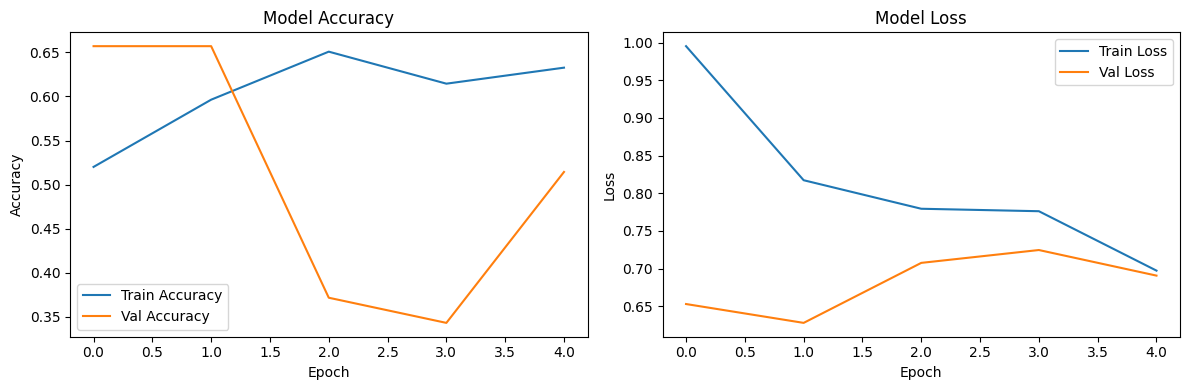

In [ ]:

# STEP 4: MODEL TRAINING

from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Compile
model.compile(
    optimizer='adam',               # adaptive optimizer
    loss='binary_crossentropy',     # for 2-class problems
    metrics=['accuracy']
)

# Early stopping — stop if val_loss doesn't improve for 3 epochs
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train
history = model.fit(
    train_data,
    epochs=20,
    validation_data=val_data,
    callbacks=[early_stop]
)

# Plot accuracy and loss curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

Accuracy  : 0.6571 (65.71%)
Precision : 0.6571
Recall    : 1.0000
F1-Score  : 0.7931

Classification Report:
              precision    recall  f1-score   support

         Cat       0.00      0.00      0.00        24
         Dog       0.66      1.00      0.79        46

    accuracy                           0.66        70
   macro avg       0.33      0.50      0.40        70
weighted avg       0.43      0.66      0.52        70



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


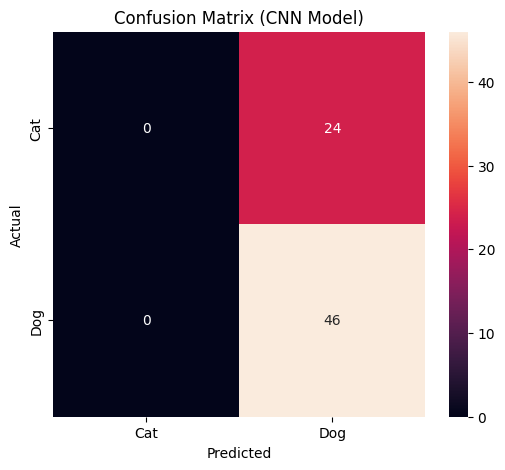

In [ ]:

# EVALUATION (NORMAL CNN)

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix, classification_report
)
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Reset generator (important)
val_data.reset()

y_true = []
y_pred = []

# Loop through validation data
for i in range(len(val_data)):
    X_batch, y_batch = val_data[i]

    predictions = model.predict(X_batch, verbose=0)

    # Convert probabilities → 0 or 1
    predictions = (predictions > 0.5).astype(int)

    y_true.extend(y_batch)
    y_pred.extend(predictions.flatten())

# Convert to numpy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)


# METRICS

accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)

print("=" * 40)
print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print("=" * 40)

# Detailed report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Cat', 'Dog']))


# CONFUSION MATRIX

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=['Cat', 'Dog'],
            yticklabels=['Cat', 'Dog'])

plt.title("Confusion Matrix (CNN Model)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 13s 846ms/step - accuracy: 0.8036 - loss: 0.4356 - val_accuracy: 0.9571 - val_loss: 0.1629
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 535ms/step - accuracy: 0.9564 - loss: 0.1202 - val_accuracy: 0.9571 - val_loss: 0.1294
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 599ms/step - accuracy: 0.9600 - loss: 0.1071 - val_accuracy: 0.9571 - val_loss: 0.1085
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 511ms/step - accuracy: 0.9709 - loss: 0.0633 - val_accuracy: 0.9571 - val_loss: 0.0839
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 681ms/step - accuracy: 0.9600 - loss: 0.1134 - val_accuracy: 0.9571 - val_loss: 0.1012
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 507ms/step - accuracy: 0.9782 - loss: 0.0548 - val_accuracy: 0.9714 - val_loss: 0.1128
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 518ms/step - accuracy: 0.9818 - loss: 0.0570 - val_accuracy: 0.9571 - val_loss: 0.1109
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 585ms/step - accuracy: 0.9855 - loss: 0.0394 - val_accuracy: 0.9429 - val_loss

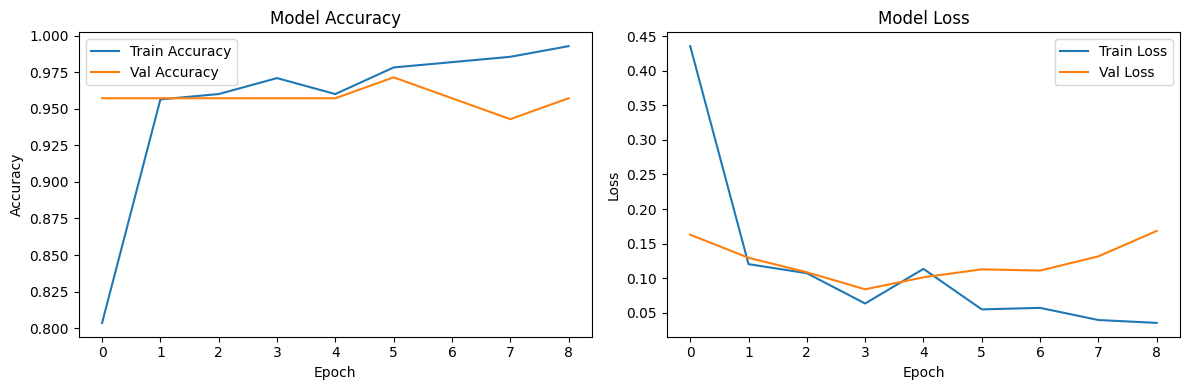

In [ ]:

# STEP 3 & 4 COMBINED - Transfer Learning with MobileNetV2

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

tf.keras.backend.clear_session()

# Load MobileNetV2 pretrained on ImageNet, without the top classifier
base_model = MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,          # remove original classifier
    weights='imagenet'          # use pretrained weights
)
base_model.trainable = False    # freeze base — don't retrain it

# Add our own classifier on top
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')  # cat=0, dog=1
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    epochs=20,
    validation_data=val_data,
    callbacks=[early_stop]
)

# Plot
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

  Accuracy  : 0.9571  (95.71%)
  Precision : 0.9574
  Recall    : 0.9783
  F1-Score  : 0.9677

Classification Report:
              precision    recall  f1-score   support

         Cat       0.96      0.92      0.94        24
         Dog       0.96      0.98      0.97        46

    accuracy                           0.96        70
   macro avg       0.96      0.95      0.95        70
weighted avg       0.96      0.96      0.96        70



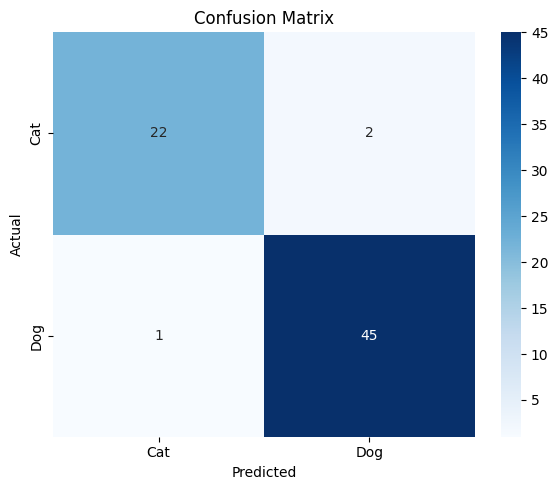

In [ ]:

# STEP 5: EVALUATION

from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, classification_report)
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Collect true labels and predictions
val_data.reset()
y_true, y_pred = [], []

for i in range(len(val_data)):
    X_batch, y_batch = val_data[i]
    preds = model.predict(X_batch, verbose=0)
    y_true.extend(y_batch.astype(int))
    y_pred.extend((preds > 0.5).astype(int).flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Metrics
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)

print("=" * 40)
print(f"  Accuracy  : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"  Precision : {precision:.4f}")
print(f"  Recall    : {recall:.4f}")
print(f"  F1-Score  : {f1:.4f}")
print("=" * 40)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Cat', 'Dog']))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cat', 'Dog'],
            yticklabels=['Cat', 'Dog'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()